# TexTune – Production Delay Prediction


## 1. Load the data

Start by loading the production orders and checking the available columns.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.base import clone
from catboost import CatBoostClassifier

SEED = 42

In [30]:
df = pd.read_csv("textune_production_orders.csv")
print("Dataset size:", df.shape)
display(df.head())

Dataset size: (800, 13)


,order_id,planned_start_date,fabric_type,color_group,quantity_kg,priority,machine_group,planned_processing_hours,machine_utilization_pct,queue_length,previous_reprocess_count,days_until_delivery,delayed
0,TT-PO-0001,2026-02-27,Cotton-Poly Blend,Dark,1500,Normal,Jet Dyeing,11.9,78.0,3,0,11,0
1,TT-PO-0002,2026-01-14,Cotton-Poly Blend,Dark,1350,High,Jet Dyeing,12.9,65.0,4,0,14,1
2,TT-PO-0003,2026-06-30,Viscose,Dark,1440,Normal,Soft Flow,12.2,86.0,6,1,12,1
3,TT-PO-0004,2026-01-17,Polyester,Light,2010,Normal,Jet Dyeing,10.8,64.0,1,0,4,0
4,TT-PO-0005,2026-04-28,Cotton,Dark,2290,Normal,Soft Flow,15.5,89.0,6,0,7,0


### Check the columns

Review data types and basic statistics to understand the dataset.

In [31]:
df.info()
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   order_id                  800 non-null    str    
 1   planned_start_date        800 non-null    str    
 2   fabric_type               800 non-null    str    
 3   color_group               800 non-null    str    
 4   quantity_kg               800 non-null    int64  
 5   priority                  800 non-null    str    
 6   machine_group             800 non-null    str    
 7   planned_processing_hours  789 non-null    float64
 8   machine_utilization_pct   786 non-null    float64
 9   queue_length              800 non-null    int64  
 10  previous_reprocess_count  800 non-null    int64  
 11  days_until_delivery       800 non-null    int64  
 12  delayed                   800 non-null    int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 81.4 KB


,quantity_kg,planned_processing_hours,machine_utilization_pct,queue_length,previous_reprocess_count,days_until_delivery,delayed
count,800.000000,789.000000,786.000000,800.000000,800.000000,800.000000,800.000000
mean,1292.375000,10.933840,73.081425,3.172500,0.428750,8.143750,0.238750
std,625.880194,2.621966,14.788823,1.715057,0.726694,3.688847,0.426586
min,180.000000,4.500000,48.000000,0.000000,0.000000,2.000000,0.000000
25%,770.000000,8.900000,60.000000,2.000000,0.000000,5.000000,0.000000
50%,1270.000000,10.900000,73.000000,3.000000,0.000000,8.000000,0.000000
75%,1840.000000,12.700000,85.000000,4.000000,1.000000,11.000000,0.000000
max,2400.000000,17.900000,98.000000,7.000000,3.000000,14.000000,1.000000


### Missing values

Check which columns have missing information before preparing the model.

In [32]:
display(df.isnull().sum().to_frame("Missing values"))

,Missing values
order_id,0
planned_start_date,0
fabric_type,0
color_group,0
quantity_kg,0
priority,0
machine_group,0
planned_processing_hours,11
machine_utilization_pct,14
queue_length,0


### Duplicate records

Check repeated rows and order IDs to identify possible data quality issues.

In [33]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate order IDs:", df["order_id"].duplicated().sum())

Duplicate rows: 0
Duplicate order IDs: 0


### Check unusual values

Review numeric ranges. Large values are not removed automatically because large orders and busy machines may be relevant to delays.

In [34]:
numeric_cols = [
    "quantity_kg", "planned_processing_hours", "machine_utilization_pct",
    "queue_length", "previous_reprocess_count", "days_until_delivery"
]
display(df[numeric_cols].describe().T)

assert df["order_id"].notna().all()
assert not df["order_id"].duplicated().any()
assert df["delayed"].notna().all() and df["delayed"].isin([0, 1]).all()
assert df["quantity_kg"].gt(0).all()
assert df["planned_processing_hours"].dropna().gt(0).all()
assert df["machine_utilization_pct"].dropna().between(0, 100).all()
assert df["queue_length"].ge(0).all()
assert df["previous_reprocess_count"].ge(0).all()
assert df["days_until_delivery"].gt(0).all()

q1 = df[numeric_cols].quantile(0.25)
q3 = df[numeric_cols].quantile(0.75)
iqr = q3 - q1
unusual = (df[numeric_cols] < q1 - 1.5 * iqr) | (df[numeric_cols] > q3 + 1.5 * iqr)
display(unusual.sum().to_frame("Possible outliers"))
print("Range checks passed. Plausible values are retained.")

,count,mean,std,min,25%,50%,75%,max
quantity_kg,800.0,1292.375000,625.880194,180.0,770.0,1270.0,1840.0,2400.0
planned_processing_hours,789.0,10.933840,2.621966,4.5,8.9,10.9,12.7,17.9
machine_utilization_pct,786.0,73.081425,14.788823,48.0,60.0,73.0,85.0,98.0
queue_length,800.0,3.172500,1.715057,0.0,2.0,3.0,4.0,7.0
previous_reprocess_count,800.0,0.428750,0.726694,0.0,0.0,0.0,1.0,3.0
days_until_delivery,800.0,8.143750,3.688847,2.0,5.0,8.0,11.0,14.0


,Possible outliers
quantity_kg,0
planned_processing_hours,0
machine_utilization_pct,0
queue_length,0
previous_reprocess_count,17
days_until_delivery,0


Range checks passed. Plausible values are retained.


## 2. Prepare the data

Keep a copy of the data, trim spaces from category names, and parse the start date. The data has 11 missing processing-hour values and 14 missing utilization values. We keep these rows and fill the numbers with the training median inside each pipeline.

Plausible large values stay in the data. The ID labels the output rows, while the date is excluded from model inputs.

In [35]:
data = df.copy()
category_cols = ["fabric_type", "color_group", "priority", "machine_group"]
for col in category_cols:
    data[col] = data[col].str.strip().replace("", np.nan)
data["planned_start_date"] = pd.to_datetime(data["planned_start_date"])
print("Start date range", data["planned_start_date"].min(), "to", data["planned_start_date"].max())

Start date range 2026-01-01 00:00:00 to 2026-06-30 00:00:00


## 3. Explore delays

The target `delayed` uses 1 for a delayed order and 0 for an on-time order.

Delay rate: 23.88 %


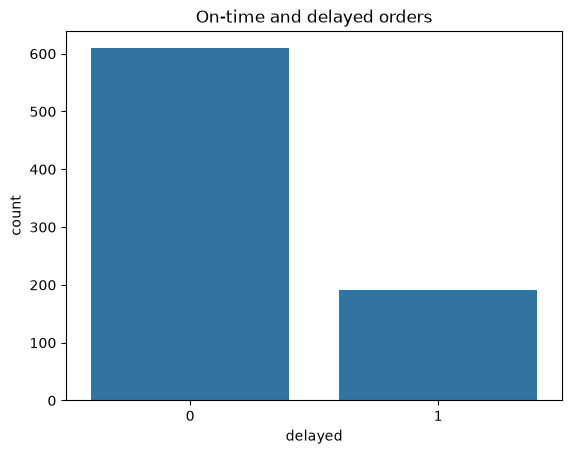

In [36]:
print("Delay rate:", round(data["delayed"].mean() * 100, 2), "%")
sns.countplot(data=data, x="delayed")
plt.title("On-time and delayed orders")
plt.show()

### Machine utilization

Compare delay rates at different levels of machine utilization.

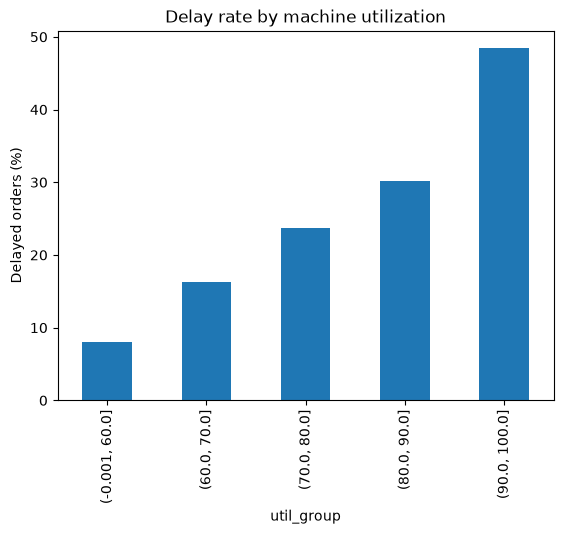

In [37]:
data["util_group"] = pd.cut(data["machine_utilization_pct"],
                            bins=[0, 60, 70, 80, 90, 100], include_lowest=True)
(data.groupby("util_group", observed=True)["delayed"].mean() * 100).plot.bar()
plt.ylabel("Delayed orders (%)")
plt.title("Delay rate by machine utilization")
plt.show()

### Queue length

Check how delay rates change as more orders wait in the queue.

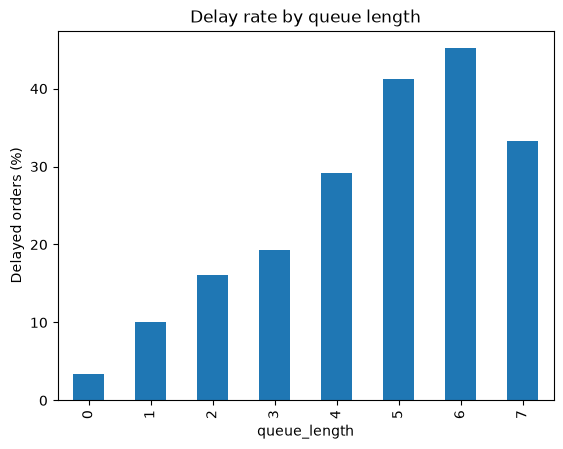

In [38]:
(data.groupby("queue_length")["delayed"].mean() * 100).plot.bar()
plt.ylabel("Delayed orders (%)")
plt.title("Delay rate by queue length")
plt.show()

### Previous reprocessing

Compare delay rates for orders with different reprocessing counts.

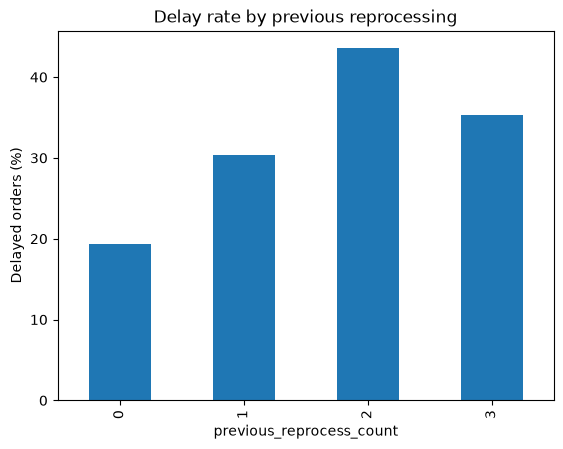

In [39]:
(data.groupby("previous_reprocess_count")["delayed"].mean() * 100).plot.bar()
plt.ylabel("Delayed orders (%)")
plt.title("Delay rate by previous reprocessing")
plt.show()

### Time left until delivery

Check whether shorter delivery windows are associated with more delays.

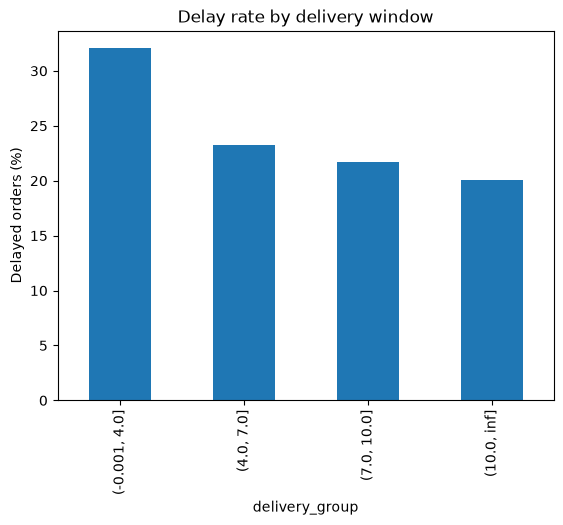

In [40]:
data["delivery_group"] = pd.cut(data["days_until_delivery"],
                                bins=[0, 4, 7, 10, np.inf], include_lowest=True)
(data.groupby("delivery_group", observed=True)["delayed"].mean() * 100).plot.bar()
plt.ylabel("Delayed orders (%)")
plt.title("Delay rate by delivery window")
plt.show()

### Compare categories

Compare delay rates across fabric, color, priority, and machine groups.

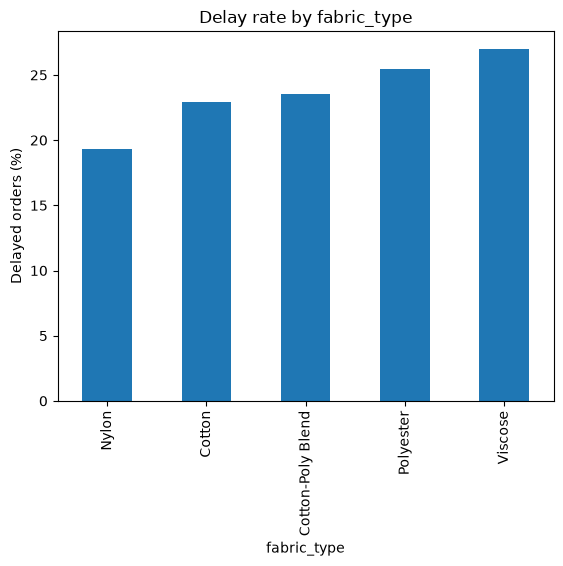

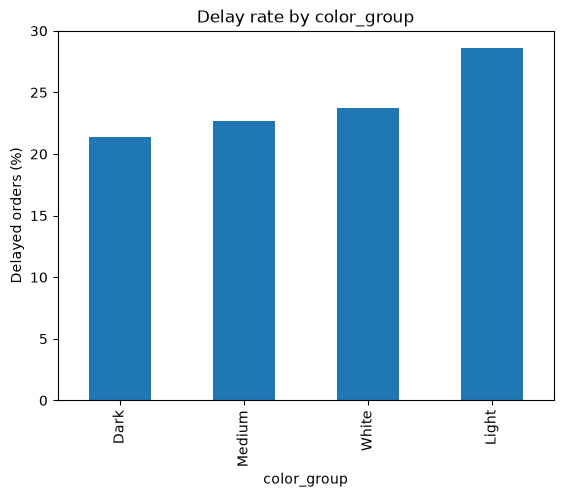

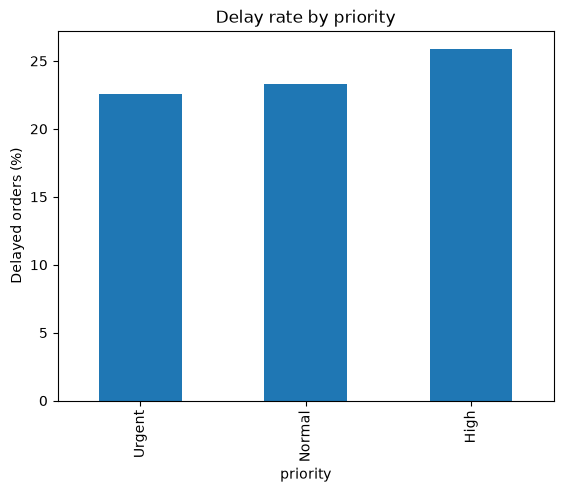

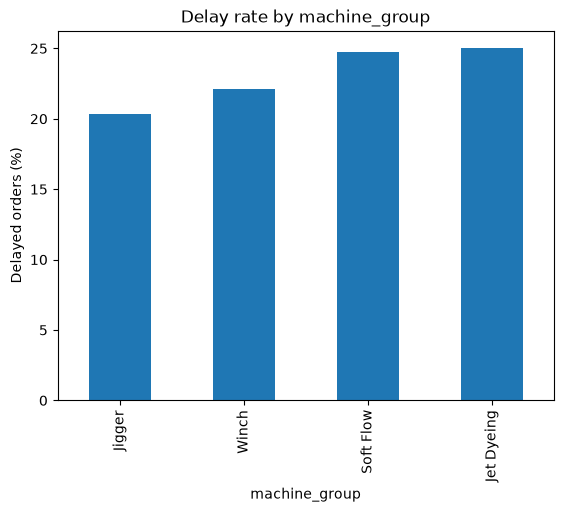

In [41]:
for col in category_cols:
    rates = data.groupby(col)["delayed"].mean().sort_values() * 100
    rates.plot.bar(title=f"Delay rate by {col}")
    plt.ylabel("Delayed orders (%)")
    plt.show()

### Machine utilization and queue length

Look at both conditions together to find combinations associated with higher delay rates.

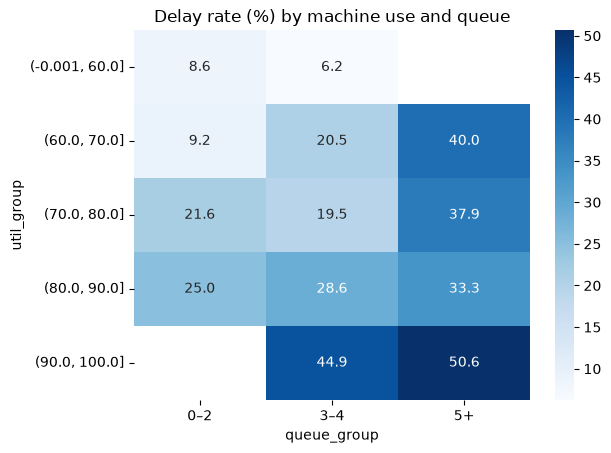

In [42]:
data["queue_group"] = pd.cut(data["queue_length"], bins=[-1, 2, 4, np.inf], labels=["0–2", "3–4", "5+"])
heat = data.pivot_table(index="util_group", columns="queue_group", values="delayed",
                        aggfunc="mean", observed=True)
sns.heatmap(heat * 100, annot=True, fmt=".1f", cmap="Blues")
plt.title("Delay rate (%) by machine use and queue")
plt.show()

In [43]:
known = data.dropna(subset=["machine_utilization_pct", "queue_length"]).copy()
known["congestion_group"] = np.where(
    (known["machine_utilization_pct"] >= 85) & (known["queue_length"] >= 5),
    "High utilization and long queue",
    "Other orders with known inputs"
)
congestion_summary = known.groupby("congestion_group")["delayed"].agg(
    order_count="size", delayed_orders="sum", delay_rate="mean"
)
display(congestion_summary.style.format({"delay_rate": "{:.1%}"}))
excluded_congestion = len(data) - len(known)
print("Orders excluded due to missing congestion inputs", excluded_congestion)

reprocess_summary = data.assign(
    reprocess_group=np.where(
        data["previous_reprocess_count"] >= 1,
        "At least one previous event", "No previous events"
    )
).groupby("reprocess_group")["delayed"].agg(
    order_count="size", delayed_orders="sum", delay_rate="mean"
)
display(reprocess_summary.style.format({"delay_rate": "{:.1%}"}))

delivery_masks = {
    "2-4 days": data["days_until_delivery"].between(2, 4),
    "11-14 days": data["days_until_delivery"].between(11, 14)
}
delivery_summary = pd.DataFrame([
    {
        "delivery_window": label,
        "order_count": int(mask.sum()),
        "delayed_orders": int(data.loc[mask, "delayed"].sum()),
        "delay_rate": data.loc[mask, "delayed"].mean()
    }
    for label, mask in delivery_masks.items()
]).set_index("delivery_window")
display(delivery_summary.style.format({"delay_rate": "{:.1%}"}))

,order_count,delayed_orders,delay_rate
congestion_group,,,
High utilization and long queue,121,56,46.3%
Other orders with known inputs,665,129,19.4%


Orders excluded due to missing congestion inputs 14


,order_count,delayed_orders,delay_rate
reprocess_group,,,
At least one previous event,247,84,34.0%
No previous events,553,107,19.3%


,order_count,delayed_orders,delay_rate
delivery_window,,,
2-4 days,181,58,32.0%
11-14 days,244,49,20.1%


### Three useful observations

1. **Machine congestion:** Orders with high machine utilization and long queues had a 46.3% delay rate, compared with 19.4% for other orders with known inputs.
2. **Previous reprocessing:** Orders with previous reprocessing events had a 34.0% delay rate, compared with 19.3% for orders without such events.
3. **Delivery time:** Orders with only 2–4 days until delivery had a 32.0% delay rate, compared with 20.1% for orders with 11–14 days.

These results suggest that machine congestion, previous reprocessing, and shorter delivery windows are associated with higher delay risk. Therefore, planners should pay additional attention to orders with these conditions.

## 4. Feature engineering

Hours per delivery day represents time pressure. Capacity pressure combines utilization with the delivery window. Queue pressure multiplies queue length by this order's own processing hours. It is a rough congestion proxy because the durations of the waiting jobs are unavailable.

These features use information assumed to be available when planning the order.

In [44]:
days = data["days_until_delivery"].clip(lower=1)
data["hours_per_day"] = data["planned_processing_hours"] / days
data["queue_pressure"] = data["queue_length"] * data["planned_processing_hours"]
data["capacity_pressure"] = data["machine_utilization_pct"] / days

## 5. Inputs and target

Use production-related columns as inputs and `delayed` as the target. Exclude the order ID because it is an identifier.

In [45]:
features = numeric_cols + ["hours_per_day", "queue_pressure", "capacity_pressure"] + category_cols
X = data[features]
y = data["delayed"].astype(int)
print("Input columns:", len(features))

Input columns: 13


### Train-test split

Keep 20% of the data for testing. Stratification preserves the proportion of delayed orders in both sets.

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Training:", len(X_train), "Testing:", len(X_test))

Training: 640 Testing: 160


### Preprocessing

Fill missing numeric values with the training median and encode categories. Keeping preprocessing inside a pipeline avoids leakage.
Numerical features are standardized using StandardScaler, while categorical features are converted into numerical form using OneHotEncoder. Both transformations are combined using ColumnTransformer.

In [47]:
numeric_features = numeric_cols + [
    "hours_per_day", "queue_pressure", "capacity_pressure"
]
num_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
cat_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])
preprocess = ColumnTransformer([
    ("num", num_pipe, numeric_features),
    ("cat", cat_pipe, category_cols)
])

## 6. Compare four models

| Model | Why it is included |
|---|---|
| Logistic Regression | A simple baseline that is quick to train and explain |
| Balanced Logistic Regression | Gives delayed orders more weight because they are the smaller class |
| Random Forest | Can learn nonlinear patterns and combinations of inputs |
| CatBoost | Builds trees in sequence to improve earlier predictions |

The models use the same train-test split and inputs. We tune a separate cutoff for each model so the comparison allows each one to balance missed delays and false warnings.

In [48]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Balanced Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5,min_samples_leaf=5, random_state=SEED),
    "CatBoost":  CatBoostClassifier(
    iterations=250,depth=4,learning_rate=0.05,
    verbose=False,random_seed=SEED,thread_count=1,
    allow_writing_files=False)
}

### Model pipelines

Apply the same preprocessing steps to every model for a fair comparison.

In [49]:
pipelines = {
    name: Pipeline([("prepare", clone(preprocess)), ("model", model)])
    for name, model in models.items()
}

## 7. Cross-validation and cutoffs

Use five training folds to generate a probability for each training order. Try cutoffs from 0.05 to 0.79 and keep the highest-F1 cutoff for each model.

Precision measures how often warnings are correct. Recall measures how many delays are caught. F1 balances both. Choosing and reporting the cutoff on the same fold predictions can make training F1 optimistic, so we reserve the test set for the final check.

In [50]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
threshold_grid = np.round(np.arange(0.05, 0.80, 0.01), 2)
thresholds = {}
cv_results = []

for name, model in pipelines.items():
    probs = cross_val_predict(
        clone(model), X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]
    scores = [
        f1_score(y_train, probs >= cutoff, zero_division=0)
        for cutoff in threshold_grid
    ]
    cutoff = float(threshold_grid[np.argmax(scores)])
    thresholds[name] = cutoff
    preds = (probs >= cutoff).astype(int)
    cv_results.append({
        "Model": name, "Cutoff": cutoff,
        "Precision": precision_score(y_train, preds, zero_division=0),
        "Recall": recall_score(y_train, preds, zero_division=0),
        "F1": f1_score(y_train, preds, zero_division=0)
    })

cv_table = pd.DataFrame(cv_results).sort_values(
    "F1", ascending=False, kind="stable"
).reset_index(drop=True)
display(cv_table.round(3))

,Model,Cutoff,Precision,Recall,F1
0,CatBoost,0.21,0.440,0.725,0.548
1,Random Forest,0.29,0.455,0.654,0.536
2,Logistic Regression,0.21,0.396,0.725,0.513
3,Balanced Logistic Regression,0.44,0.391,0.739,0.511


### Select the model

Choose the model with the highest cross-validation F1-score before evaluating the test set. This avoids choosing a model based on test performance.

The final choice stays fixed after test evaluation, even when another model has a higher test score.

In [51]:
best_name = cv_table.iloc[0]["Model"]
best_cutoff = thresholds[best_name]
print("Selected model", best_name)
print("Selected cutoff", best_cutoff)

Selected model CatBoost
Selected cutoff 0.21


## 8. Test-set evaluation

Fit each model on the training data and compare its predictions on the held-out test set.

In [52]:
fitted = {}
test_predictions = {}
test_probabilities = {}
results = []

for name, model in pipelines.items():
    fitted_model = clone(model).fit(X_train, y_train)
    fitted[name] = fitted_model
    probs = fitted_model.predict_proba(X_test)[:, 1]
    preds = (probs >= thresholds[name]).astype(int)
    test_probabilities[name] = probs
    test_predictions[name] = preds
    results.append({
        "Model": name, "Cutoff": thresholds[name],
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0)
    })

test_table = pd.DataFrame(results)
display(test_table.round(3))
print(f"Always predicting on time gives {(1 - y_test.mean()):.1%} accuracy and catches no delays.")
for name in fitted:
    print("\n" + name)
    print(classification_report(
        y_test, test_predictions[name], labels=[0, 1],
        target_names=["On time", "Delayed"], zero_division=0
    ))

,Model,Cutoff,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.21,0.612,0.338,0.658,0.446
1,Balanced Logistic Regression,0.44,0.625,0.359,0.737,0.483
2,Random Forest,0.29,0.650,0.355,0.579,0.440
3,CatBoost,0.21,0.600,0.333,0.684,0.448


Always predicting on time gives 76.2% accuracy and catches no delays.

Logistic Regression
              precision    recall  f1-score   support

     On time       0.85      0.60      0.70       122
     Delayed       0.34      0.66      0.45        38

    accuracy                           0.61       160
   macro avg       0.59      0.63      0.57       160
weighted avg       0.73      0.61      0.64       160


Balanced Logistic Regression
              precision    recall  f1-score   support

     On time       0.88      0.59      0.71       122
     Delayed       0.36      0.74      0.48        38

    accuracy                           0.62       160
   macro avg       0.62      0.66      0.59       160
weighted avg       0.75      0.62      0.65       160


Random Forest
              precision    recall  f1-score   support

     On time       0.84      0.67      0.75       122
     Delayed       0.35      0.58      0.44        38

    accuracy                           0.65   

### Confusion matrix

The confusion matrix shows correctly detected delays, missed delays, and false alarms.

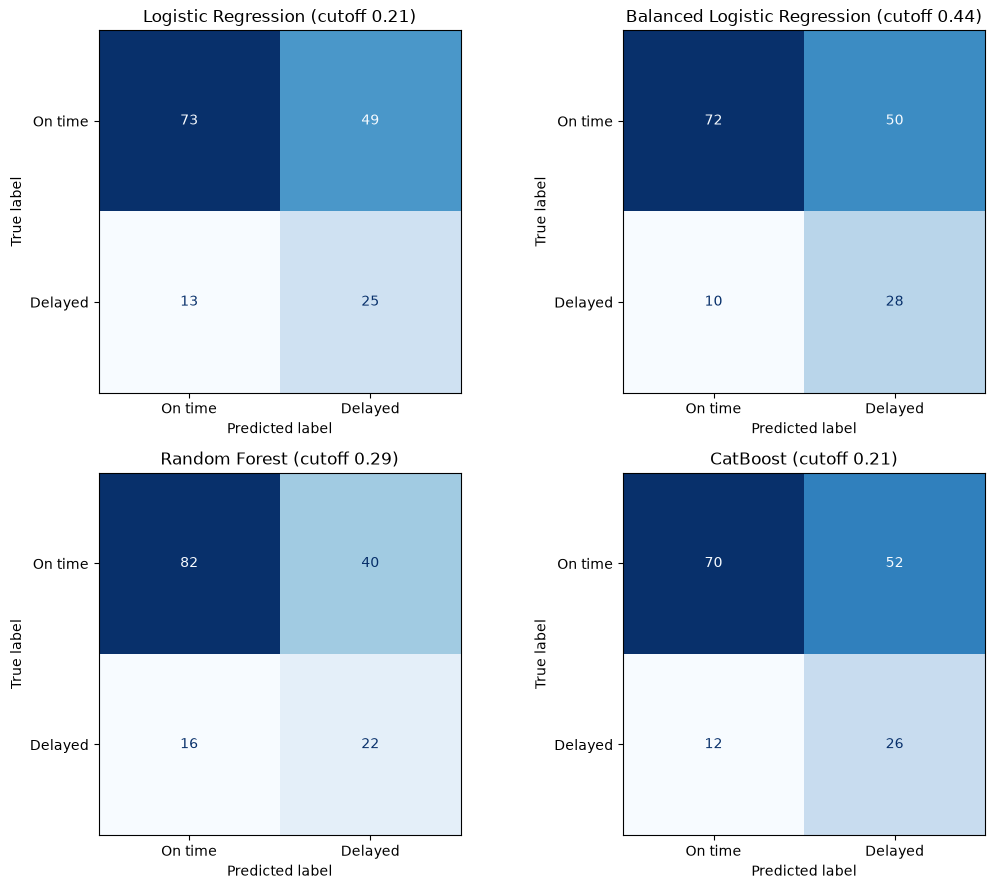

In [53]:
best_model = fitted[best_name]
test_probs = test_probabilities[best_name]
test_preds = test_predictions[best_name]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.flat, fitted):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions[name], labels=[0, 1],
        display_labels=["On time", "Delayed"],
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(f"{name} (cutoff {thresholds[name]:.2f})")
plt.tight_layout()
plt.show()

### Top-20 test orders

Check how many delayed orders appear among the 20 highest-risk orders in the test set.

In [54]:
top_positions = np.argsort(-test_probs, kind="stable")[:20]
found = int(y_test.iloc[top_positions].sum())
precision_at_20 = found / 20
recall_at_20 = found / y_test.sum()
print("Actual delayed orders in the top 20", found)
print(f"Precision at 20 {precision_at_20:.1%}")
print(f"Recall at 20 {recall_at_20:.1%}")

Actual delayed orders in the top 20 9
Precision at 20 45.0%
Recall at 20 23.7%


### Final Model Selection

I selected CatBoost because it achieved the highest training cross-validation F1-score of 0.548 among the four models.

On the test set, CatBoost achieved an F1-score of 0.448 and recall of 68.4%.

Balanced Logistic Regression performed better on the test set, achieving an F1-score of 0.483 and recall of 73.7%. This suggests that the simpler model is also a promising option.

However, I kept CatBoost as the final model because it was selected using training cross-validation rather than test results. Further validation would help determine which model generalizes better.

## 9. Delay-risk scores and planner review list

The selected CatBoost model is used to estimate the delay risk of each order. Orders are ranked by their predicted delay risk score, and the top 20 highest-risk orders are selected for planner review.

Five-fold out-of-fold predictions are used so each order is scored by a model that was not trained on that order.

Since these are historical orders with known outcomes, this demonstrates how planners could identify orders that may need attention.

The predicted class is determined using the selected cutoff of **0.21**, while ranking is based on the predicted probability.

These scores represent estimated risk, not guaranteed probabilities, because probability calibration has not been evaluated.

In [55]:
all_probs = cross_val_predict(
    clone(pipelines[best_name]), X, y, cv=cv, method="predict_proba"
)[:, 1]

planner_columns = [
    "order_id", "machine_group", "priority", "queue_length",
    "machine_utilization_pct", "previous_reprocess_count", "days_until_delivery"
]
ranked_orders = data[planner_columns].copy()
ranked_orders["predicted_delay_probability"] = all_probs
ranked_orders["predicted_class"] = (all_probs >= best_cutoff).astype(int)
ranked_orders = ranked_orders.sort_values(
    "predicted_delay_probability", ascending=False, kind="stable"
).reset_index(drop=True)
ranked_orders.insert(0, "risk_rank", np.arange(1, len(ranked_orders) + 1))
top20 = ranked_orders.head(20).copy()

print("Selected model", best_name)
print(f"Classification cutoff {best_cutoff:.2f}")
print("Orders scored", len(ranked_orders))
display(top20.style.format({
    "predicted_delay_probability": "{:.2f}",
    "machine_utilization_pct": "{:.1f}",
    "days_until_delivery": "{:.0f}"
}, na_rep="Missing"))

Selected model CatBoost
Classification cutoff 0.21
Orders scored 800


,risk_rank,order_id,machine_group,priority,queue_length,machine_utilization_pct,previous_reprocess_count,days_until_delivery,predicted_delay_probability,predicted_class
0,1,TT-PO-0477,Jigger,Normal,6,98.0,3,7,0.97,1
1,2,TT-PO-0057,Jet Dyeing,High,5,82.0,1,2,0.90,1
2,3,TT-PO-0028,Jigger,Normal,7,98.0,0,13,0.89,1
3,4,TT-PO-0113,Jigger,High,4,96.0,0,2,0.89,1
4,5,TT-PO-0093,Soft Flow,Normal,6,95.0,0,2,0.88,1
5,6,TT-PO-0117,Jet Dyeing,Normal,6,97.0,1,3,0.81,1
6,7,TT-PO-0714,Winch,Normal,4,98.0,1,5,0.81,1
7,8,TT-PO-0483,Jet Dyeing,Normal,4,89.0,1,2,0.80,1
8,9,TT-PO-0555,Winch,Normal,4,95.0,0,8,0.80,1
9,10,TT-PO-0640,Jet Dyeing,Normal,6,85.0,2,2,0.79,1


### Export the top 20

Save the highest-risk historical orders to a CSV file for review.

In [56]:
submission_columns = [
    "order_id", "predicted_delay_probability", "predicted_class"
]
submission = top20[submission_columns].copy()
assert len(submission) == 20
assert submission["order_id"].is_unique
assert submission["predicted_delay_probability"].between(0, 1).all()
assert submission["predicted_class"].isin([0, 1]).all()
assert submission["predicted_delay_probability"].is_monotonic_decreasing
submission["predicted_delay_probability"] = submission["predicted_delay_probability"].round(2)
submission.to_csv("top_20_at_risk_orders.csv", index=False)
print("Saved top_20_at_risk_orders.csv")

Saved top_20_at_risk_orders.csv


## 10. Planner recommendation

**Recommendation: Check machine capacity and reassign orders when possible.**

Each morning, production planners can review the 20 orders with the highest predicted delay risk.

For high-risk orders, they can check whether another suitable machine has available capacity. Orders with urgent delivery dates should receive extra attention.

Before reassigning an order, planners should consider machine compatibility, availability, setup time, and the effect on other orders. The final decision should always be made by the planner.

In this assignment, the top 20 list is generated using historical data. In a real production environment, the same approach could be used to identify unfinished orders that may need early attention.

### Why review congested machines first?

Orders with **85% or higher machine utilization** and **five or more waiting orders** had a **46.3% delay rate**, compared with **19.4%** for other orders with available data. The comparison excludes 14 orders with missing information.

On the test set, CatBoost correctly identified **26 out of 38 delayed orders**, missed 12, and produced 52 false warnings.

This suggests that machine congestion is an important factor to consider. However, since the model can give false warnings, planners should check machine availability, compatibility, and workload before reassigning orders.

## Assumptions and Limitations

- **Data availability:** Machine utilization, queue length, processing time, and delivery information are assumed to be available when an order is planned. Reprocessing counts refer only to earlier events.
- **Missing values:** Missing numerical values are filled using training-data medians, and missing categorical values use the most common training category. Rows with missing congestion information are excluded from the congestion comparison but retained for model training.
- **Dataset size:** The dataset contains only 800 synthetic orders. Results may differ with real production data.
- **Missing factors:** Machine breakdowns, staff availability, and material shortages are not included.
- **Data leakage risk:** Some exploratory analysis and feature decisions used the full dataset before the train-test split. Although the test data was excluded from model fitting and threshold selection, it may have influenced the analysis. Future work should perform target-based EDA using training data only.
- **Model selection:** Selecting the cutoff and evaluating F1 using the same cross-validation predictions may give optimistic validation results.
- **Risk ranking:** The top-20 list demonstrates how the model could support planners, but it is not an independent evaluation of future performance.
- **Evaluation:** F1 treats precision and recall equally, but real production decisions may place greater importance on avoiding missed delays.
- **Probability estimates:** Predicted probabilities have not been calibrated, so they should be treated as risk scores rather than exact delay probabilities.

Further testing on new, real production data would help confirm the model's reliability.